# ÁRBOLES DE DECISIÓN
### NOMBRE: Carlos Enrique Nieves Ochoa
### EXPEDIENTE: 758210
### FECHA: 12 de Noviembre de 2026

In [253]:
#Librerías
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import numpy as np

In [254]:
#Lectura del archivo
df = pd.read_excel("DATASET-SALON.xlsx")
df.head()

,Género,Edad,Estatura
0,M,21,1.80
1,M,21,1.76
2,M,22,1.82
3,M,20,1.67
4,F,22,1.75


## Cálculo de la varianza de la estatura por género

Separo el salón por género para calcular la varianza de la estatura en cada grupo.

In [255]:
# Separar por género
hombres = df.loc[df["Género"] == "M"]
mujeres = df.loc[df["Género"] == "F"]
print("Hombres:", len(hombres))
print("Mujeres:", len(mujeres))

Hombres: 7
Mujeres: 2


Calculo la varianza muestral con la suma de las diferencias al cuadrado respecto a la media, dividida entre n - 1.

In [256]:
# Varianza de la estatura por género
var_h = ((hombres["Estatura"] - hombres["Estatura"].mean())**2).sum() / (len(hombres) - 1)
var_m = ((mujeres["Estatura"] - mujeres["Estatura"].mean())**2).sum() / (len(mujeres) - 1)

res = pd.DataFrame({
    "Género": ["Hombres", "Mujeres"],
    "Varianza de la estatura": [var_h, var_m]
})
display(res.round(4))

,Género,Varianza de la estatura
0,Hombres,0.0039
1,Mujeres,0.0008


## Umbral que minimiza la varianza conjunta

Defino la función objetivo, que recibe un umbral x, separa a los alumnos con edad menor a x de los mayores, calcula la varianza de la edad en cada grupo y regresa la suma de las dos. La varianza es muestral, con la suma de las diferencias al cuadrado dividida entre n - 1, igual que en la primera parte.

In [257]:
# Función objetivo
def objetivo(x):
    grupo1 = df.loc[df["Edad"] < x, "Edad"]
    v1 = ((grupo1 - grupo1.mean())**2).sum() / (len(grupo1) - 1)

    grupo2 = df.loc[df["Edad"] > x, "Edad"]
    v2 = ((grupo2 - grupo2.mean())**2).sum() / (len(grupo2) - 1)

    return v1 + v2

Hago la búsqueda de rejilla con 20.5 y 21.5 años como umbrales, que son los puntos medios entre 20 y 21 y entre 21 y 22, y me quedo con el que da la menor varianza.

In [258]:
# Búsqueda de rejilla
rejilla = [20.5, 21.5]
resultados = []

for x in rejilla:
    resultados.append([x, objetivo(x)])

res_umbral = pd.DataFrame(resultados, columns=["Umbral", "v1 + v2"])
display(res_umbral.round(5))

,Umbral,v1 + v2
0,20.5,6.55
1,21.5,8.90


In [259]:
# Umbral con la menor varianza
mejor = res_umbral.loc[res_umbral["v1 + v2"] == res_umbral["v1 + v2"].min()]
display(mejor.round(5))

,Umbral,v1 + v2
0,20.5,6.55


El umbral que minimiza la varianza es 20.5 años, con v1 + v2 de 6.55 frente a 8.9 con 21.5, y separa a los 4 alumnos de 20 años o menos de los 5 mayores.

## Árbol de decisión

Armo el árbol con el umbral de 20.5 años en la raíz y después separo cada rama por género. Cada hoja predice la estatura con el promedio de los alumnos que caen en ella.

In [260]:
# Ramas del primer corte por edad
menores = df.loc[df["Edad"] < 20.5]
mayores = df.loc[df["Edad"] > 20.5]

# Hojas: estatura promedio por género en cada rama
ramas = [("Edad < 20.5", menores), ("Edad > 20.5", mayores)]
hojas = []

for nombre, rama in ramas:
    for g in ["M", "F"]:
        grupo = rama.loc[rama["Género"] == g]
        print(nombre, "-", g)
        display(grupo)
        hojas.append([nombre, g, len(grupo), grupo["Estatura"].mean()])

arbol = pd.DataFrame(hojas, columns=["Rama", "Género", "Alumnos", "Estatura promedio"])
display(arbol.round(4))

Edad < 20.5 - M


,Género,Edad,Estatura
3,M,20,1.67
7,M,20,1.66
8,M,20,1.75


Edad < 20.5 - F


,Género,Edad,Estatura
5,F,19,1.71


Edad > 20.5 - M


,Género,Edad,Estatura
0,M,21,1.80
1,M,21,1.76
2,M,22,1.82
6,M,27,1.79


Edad > 20.5 - F


,Género,Edad,Estatura
4,F,22,1.75


,Rama,Género,Alumnos,Estatura promedio
0,Edad < 20.5,M,3,1.6933
1,Edad < 20.5,F,1,1.7100
2,Edad > 20.5,M,4,1.7925
3,Edad > 20.5,F,1,1.7500


Del lado de los menores de 20.5 años los 3 hombres tienen una estatura promedio de 1.6933 y la única mujer mide 1.71. Del lado de los mayores los 4 hombres promedian 1.7925 y la mujer mide 1.75. Las dos hojas de mujeres tienen un solo alumno, así que su predicción es su propia estatura.

## Regresión lineal múltiple con dataset Advertising

In [261]:
advertising = pd.read_csv("advertising.csv")
display(advertising.head())

lr = LinearRegression()
X = advertising[["TV", "radio", "newspaper"]]
y = advertising["sales"]

lr.fit(X, y)
print("Intercept:", lr.intercept_)
print("Coefficients:", lr.coef_)
r_squared = lr.score(X, y)
print("R-squared:", r_squared)

,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


Intercept: 2.938889369459412
Coefficients: [ 0.04576465  0.18853002 -0.00103749]
R-squared: 0.8972106381789522


La regresión lineal me da un R² de 0.897 con todo el dataset. Radio es el que más pesa en las ventas (0.189 por unidad), luego TV (0.046), y newspaper casi no aporta porque su coeficiente es prácticamente cero (-0.001).

## Utilizando un árbol de decisión para regresión

In [262]:
dtr = DecisionTreeRegressor(random_state=67)
dtr.fit(X, y)
r_squared_dtr = dtr.score(X, y)
print("R-squared (Decision Tree):", r_squared_dtr)

R-squared (Decision Tree): 1.0


El árbol me sale con un R² de 1, o sea que ajusta perfecto los datos con los que se entrenó. Eso no quiere decir que sea mejor modelo, porque sin límite de profundidad crece hasta que cada hoja se queda con muy pocas observaciones y básicamente se aprende los datos de memoria.

## Gráfica del árbol

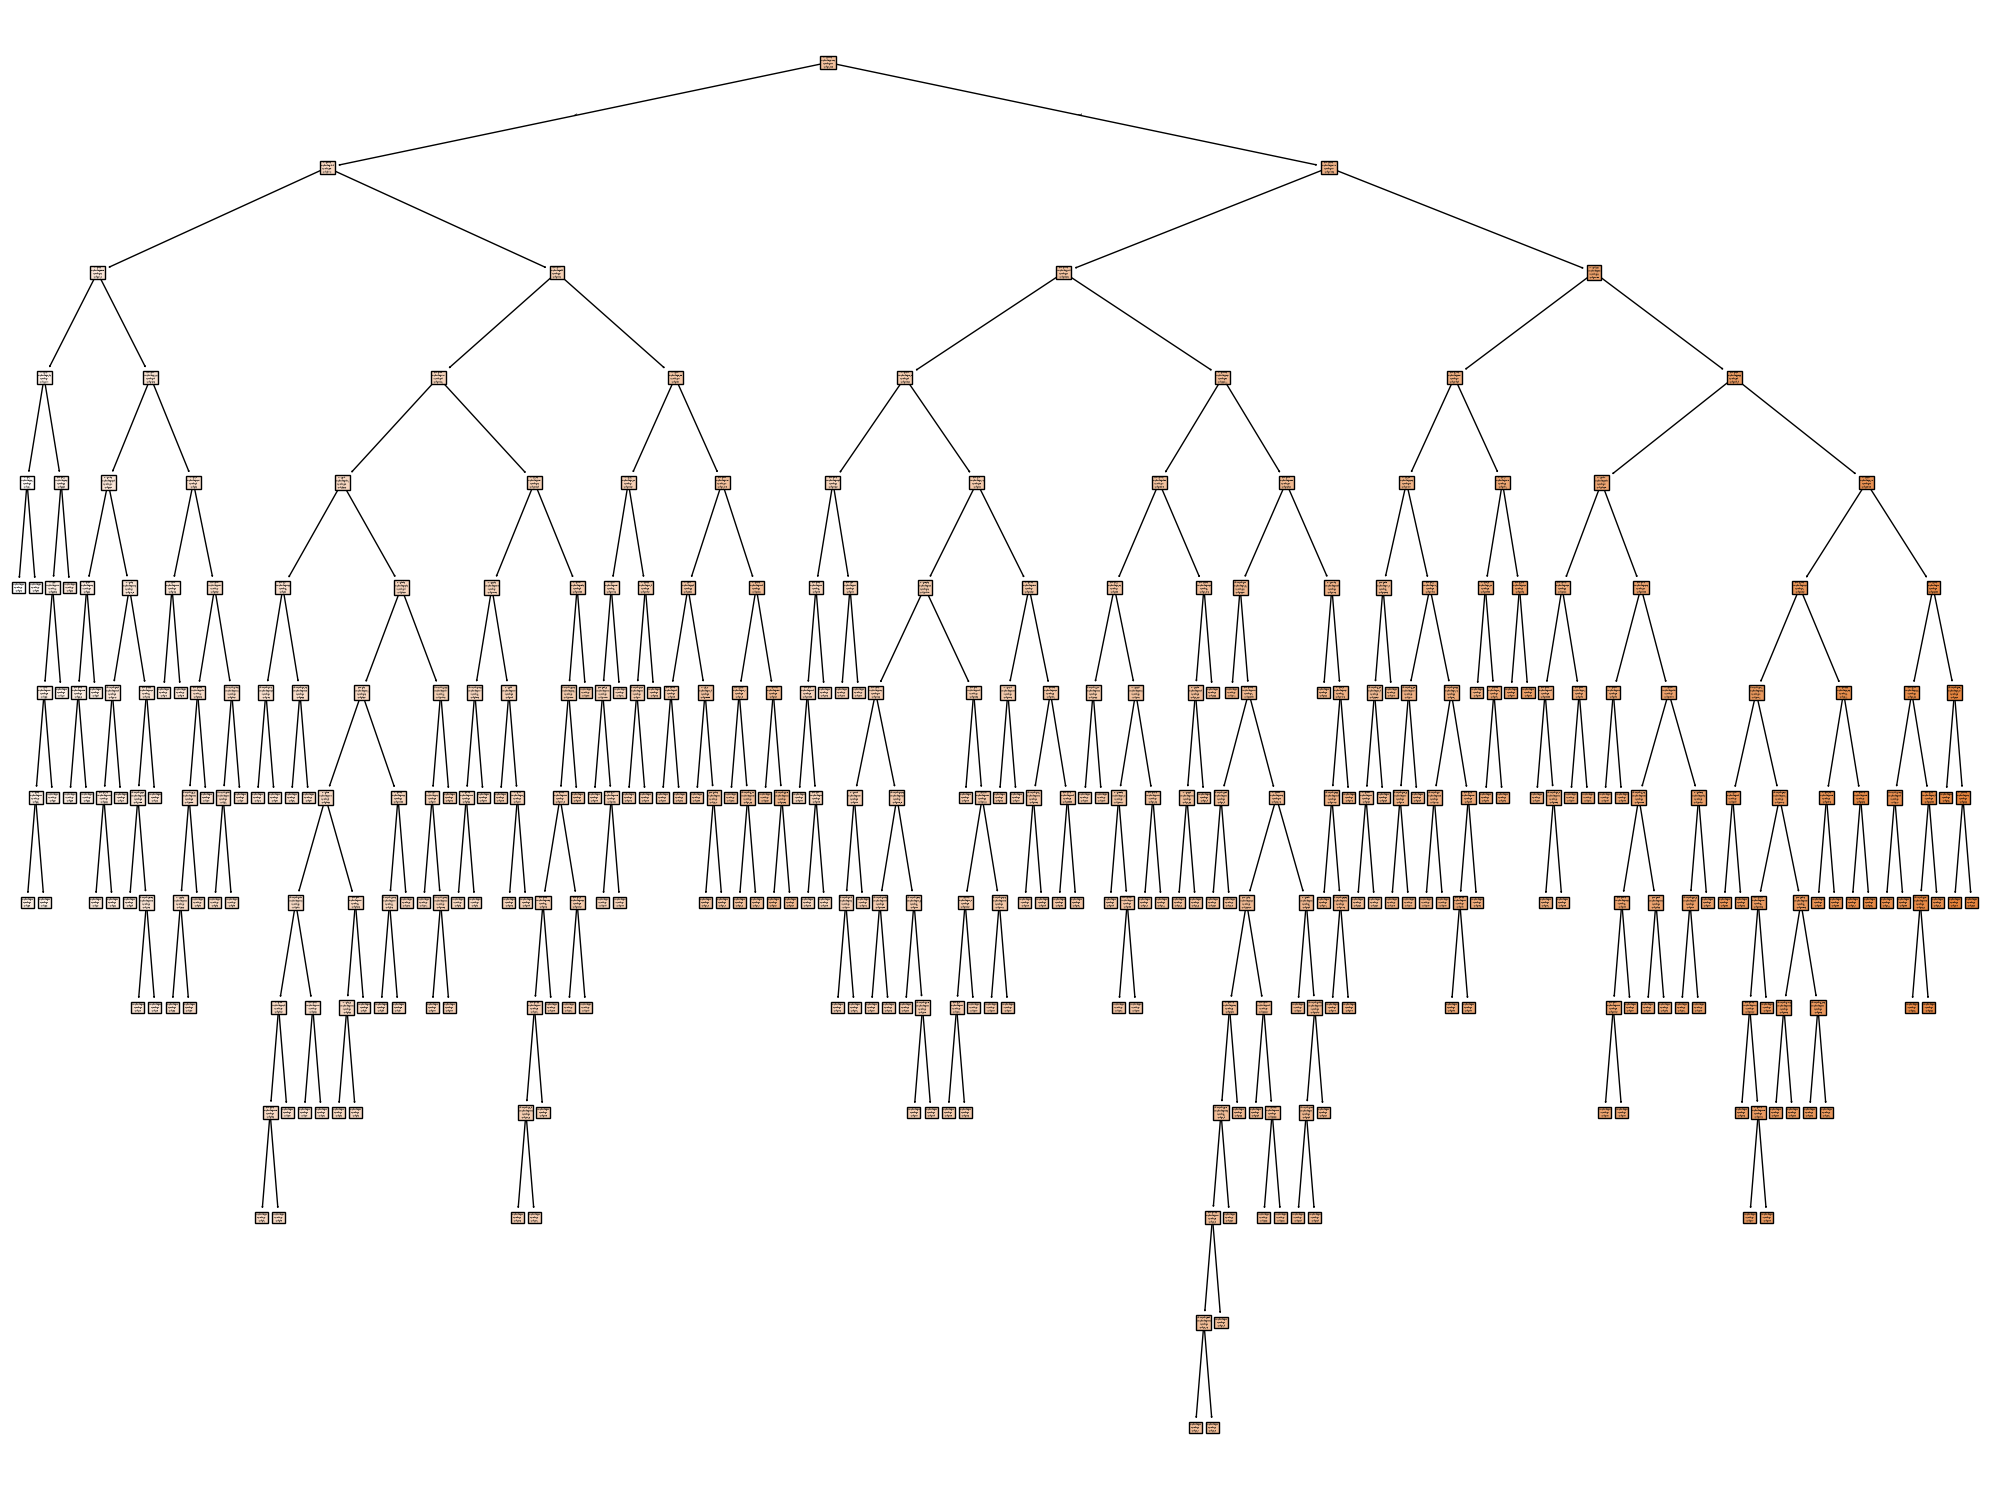

In [263]:
plt.figure(figsize=(20,15))
plot_tree(dtr, feature_names=X.columns, filled=True)
plt.tight_layout()
plt.show()

En la gráfica se ve lo grande que queda el árbol, con muchísimos niveles y hojas, ya que no le puse ningún límite de profundidad. Así es casi imposible de leer y confirma que está sobreajustado.

## Cross validation 50 50

In [264]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=67)

In [265]:
lr.fit(X_train, y_train)
r_squared_lr_train = lr.score(X_train, y_train)
r_squared_lr_test = lr.score(X_test, y_test)
print("R-squared (Linear Regression) - Train:", r_squared_lr_train)
print("R-squared (Linear Regression) - Test:", r_squared_lr_test)

R-squared (Linear Regression) - Train: 0.9140145074613925
R-squared (Linear Regression) - Test: 0.8689022417170023


Con la mitad de los datos para entrenar, la regresión lineal da 0.914 en train y 0.869 en test, así que pierde un poco con datos nuevos pero se mantiene estable.

In [266]:
dtr.fit(X_train, y_train)
r_squared_dtr_train = dtr.score(X_train, y_train)
r_squared_dtr_test = dtr.score(X_test, y_test)
print("R-squared (Decision Tree) - Train:", r_squared_dtr_train)
print("R-squared (Decision Tree) - Test:", r_squared_dtr_test)

R-squared (Decision Tree) - Train: 1.0
R-squared (Decision Tree) - Test: 0.9238347368834162


El árbol vuelve a dar 1 en train, pero en test baja a 0.924. Aunque se sobreajusta, con datos que no vio predice mejor que la regresión lineal.

## Comparativa entre modelos

In [267]:
comparativa = pd.DataFrame({
    "Modelo": ["Linear Regression", "Decision Tree"],
    "R-squared Train": [r_squared_lr_train, r_squared_dtr_train],
    "R-squared Test": [r_squared_lr_test, r_squared_dtr_test]
})

comparativa

,Modelo,R-squared Train,R-squared Test
0,Linear Regression,0.914015,0.868902
1,Decision Tree,1.000000,0.923835


En test el árbol gana con 0.924 frente a 0.869 de la regresión lineal, así que para Advertising me quedo con el árbol. Tiene sentido porque la relación de las ventas con TV y radio no es del todo lineal y el árbol la captura mejor, aunque la diferencia de 1 contra 0.924 entre train y test deja ver que sigue sobreajustado.